[*********************100%***********************]  2 of 2 completed


Cointegration test p‑value: 0.2429
Observations after feature/target creation: 1390
Base rate (spread narrows) = 51.22%

=== Performance Summary ===
Accuracy                 : 0.5086206896551724
Signal Frequency         : 0.16091954022988506
Sharpe (strategy)        : -1.0912497496439264
Sharpe (raw spread)      : 0.39466744878801946
Max DD (strategy)        : -0.30963925614044024
Max DD (raw spread)      : -0.21098751100623986
Cumulative Return (strategy): 0.6962943943532935
Cumulative Return (raw spread): 1.2320757529783155


/Users/aryhaashaari/Documents/Projects/WallStreetQuant/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


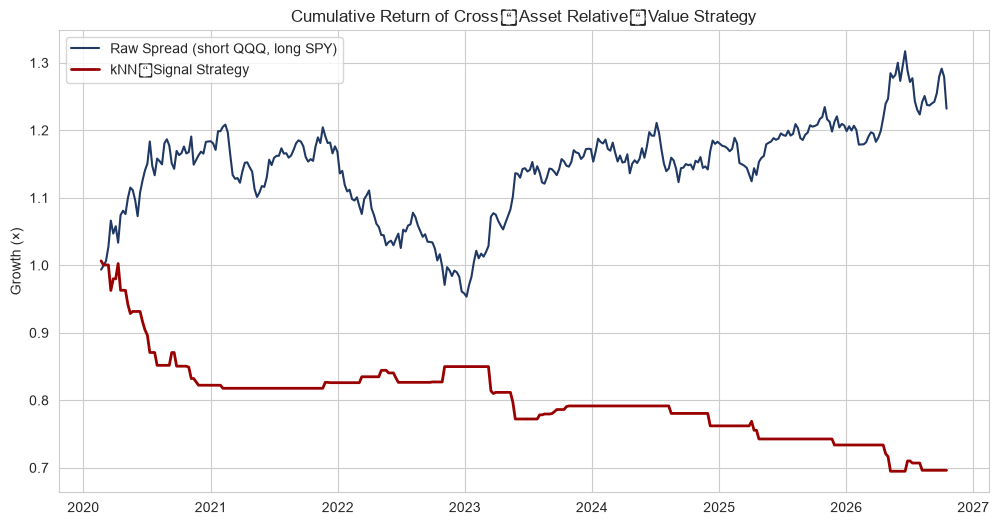

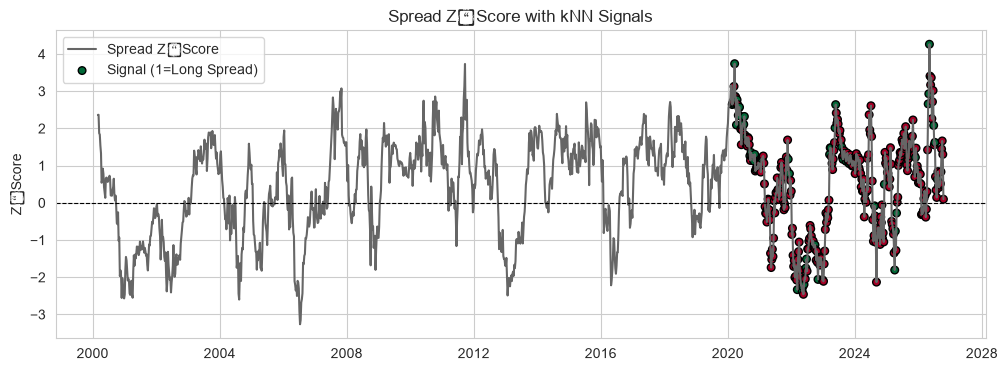

/var/folders/r_/bh6ngv4j41zbkmn2x41c9cnc0000gn/T/ipykernel_28364/405501744.py:191: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.tight_layout()
/Users/aryhaashaari/Documents/Projects/WallStreetQuant/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


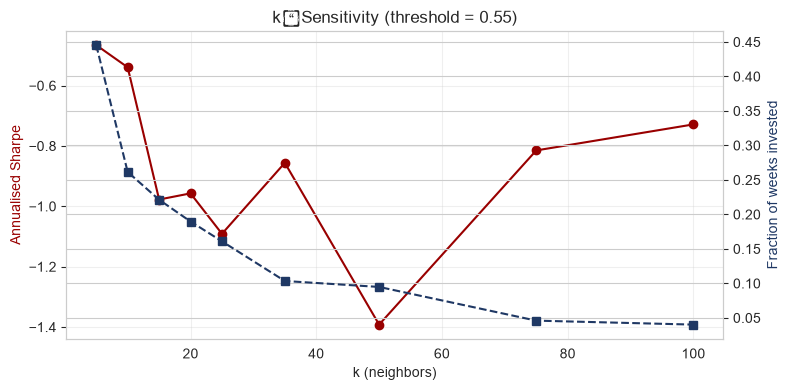

In [ ]:
# --------------------------------------------------------------
# Cross‑Asset Relative‑Value (Spread) Mean‑Reversion with kNN
# --------------------------------------------------------------
# Pair: QQQ (Nasdaq‑100) vs. SPY (S&P‑500)
# --------------------------------------------------------------

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import coint

# ------------------------------------------------------------------
# DATA ACQUISITION
# ------------------------------------------------------------------
tickers = ["QQQ", "SPY"]
price = yf.download(tickers, start="1990-01-01")["Close"]
price = price.dropna()                     # keep only days where both exist
price = price.resample("W-FRI").last()    # weekly data (Friday close)

# ------------------------------------------------------------------
# SPREAD CONSTRUCTION & COINTEGRATION CHECK
# ------------------------------------------------------------------
# Log‑price ratio is the usual stationary spread
price["log_spread"] = np.log(price["QQQ"] / price["SPY"])

# Engle‑Granger test (p‑value < 0.05 → cointegrated)
coint_t, pvalue, _ = coint(price["QQQ"], price["SPY"])
print(f"Cointegration test p‑value: {pvalue:.4f}")

# ------------------------------------------------------------------
# FEATURE ENGINEERING (all stationary)
# ------------------------------------------------------------------
df = pd.DataFrame(index=price.index)

# --- Spread‑centric features ------------------------------------------------
window = 52  # 1‑year rolling window for statistics

df["spread"]          = price["log_spread"]
df["spread_z"]        = (df["spread"] - df["spread"].rolling(window).mean()) \
                        / df["spread"].rolling(window).std()
df["spread_ret_1w"]   = df["spread"].diff(1)          # weekly change of spread
df["spread_ret_4w"]   = df["spread"].diff(4)          # 4‑week momentum of spread
df["spread_vol"]      = df["spread_ret_1w"].rolling(4).std()  # short‑term vol

# --- Individual‑asset features (optional, improve signal) --------------------
# Returns & volatility for each leg (helps the model know if a move is
# driven by a genuine regime shift or just a spread wobble)
for t in tickers:
    df[f"{t}_ret_1w"]  = price[t].pct_change(1)
    df[f"{t}_ret_4w"]  = price[t].pct_change(4)
    df[f"{t}_vol"]     = df[f"{t}_ret_1w"].rolling(4).std()
    df[f"{t}_dist_ma10"]= price[t] / price[t].rolling(10).mean() - 1
    df[f"{t}_dist_ma40"]= price[t] / price[t].rolling(40).mean() - 1

# ------------------------------------------------------------------
# TARGET VARIABLE
# ------------------------------------------------------------------
# We want to know whether the spread will **narrow** next week.
# Narrow = spread_z moves toward zero (i.e., absolute value shrinks).
df["spread_z_next"] = df["spread_z"].shift(-1)
df["target"] = (df["spread_z_next"].abs() < df["spread_z"].abs()).astype(int)

df = df.dropna()
print(f"Observations after feature/target creation: {len(df)}")
print(f"Base rate (spread narrows) = {df['target'].mean():.2%}")

# ------------------------------------------------------------------
# TRAIN / TEST SPLIT
# ------------------------------------------------------------------
split_idx = int(len(df) * 0.75)          # 75 % train, 25 % test
train = df.iloc[:split_idx]
test  = df.iloc[split_idx:]

feature_cols = [c for c in df.columns if c not in ["target", "spread_z_next"]]

# ------------------------------------------------------------------
# STANDARDISE FEATURES (fit on train only)
# ------------------------------------------------------------------
scaler = StandardScaler()
X_train = scaler.fit_transform(train[feature_cols])
X_test  = scaler.transform(test[feature_cols])

y_train = train["target"].values
y_test  = test["target"].values

# ------------------------------------------------------------------
# FIT kNN CLASSIFIER
# ------------------------------------------------------------------
knn = KNeighborsClassifier(n_neighbors=25, weights="distance")
knn.fit(X_train, y_train)

# ------------------------------------------------------------------
# OUT‑OF‑SAMPLE SIGNALS
# ------------------------------------------------------------------
# Probability that the spread will narrow next week
test["prob_narrow"] = knn.predict_proba(X_test)[:, 1]

# Choose a confidence threshold – higher = fewer trades, higher conviction
THRESH = 0.55
test["signal"] = (test["prob_narrow"] > THRESH).astype(int)   # 1 = go long spread (short QQQ, long SPY)

# Translate signal into P&L:
#   Long spread  →  profit = -(Δlog(QQQ) - Δlog(SPY)) = -(spread_ret_1w)
#   Flat         →  profit = 0
test["spread_ret_1w"] = price["log_spread"].diff(1).loc[test.index]
test["strategy_ret"] = -test["signal"] * test["spread_ret_1w"]   # negative because we short the high‑priced leg

# ------------------------------------------------------------------
# PERFORMANCE METRICS
# ------------------------------------------------------------------
def annualised_sharpe(ret, periods=52):
    mu = ret.mean()
    sigma = ret.std()
    return np.sqrt(periods) * mu / sigma if sigma != 0 else np.nan

def max_dd(cum_ret):
    peak = cum_ret.cummax()
    return ((cum_ret - peak) / peak).min()

# Cumulative returns (starting at 1.0)
cum_strategy = (1 + test["strategy_ret"]).cumprod()
cum_spread   = (1 + test["spread_ret_1w"]).cumprod()   # pure spread exposure (no signal)

metrics = {
    "Accuracy": (knn.predict(X_test) == y_test).mean(),
    "Signal Frequency": test["signal"].mean(),
    "Sharpe (strategy)": annualised_sharpe(test["strategy_ret"]),
    "Sharpe (raw spread)": annualised_sharpe(test["spread_ret_1w"]),
    "Max DD (strategy)": max_dd(cum_strategy),
    "Max DD (raw spread)": max_dd(cum_spread),
    "Cumulative Return (strategy)": cum_strategy.iloc[-1],
    "Cumulative Return (raw spread)": cum_spread.iloc[-1],
}
print("\n=== Performance Summary ===")
for k, v in metrics.items():
    print(f"{k:<25}: {v}")

# ------------------------------------------------------------------
# VISUALISATION
# ------------------------------------------------------------------
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))
plt.plot(cum_spread.index, cum_spread, label="Raw Spread (short QQQ, long SPY)", color="#1F3864")
plt.plot(cum_strategy.index, cum_strategy, label="kNN‑Signal Strategy", color="#990000", lw=2)
plt.title("Cumulative Return of Cross‑Asset Relative‑Value Strategy")
plt.ylabel("Growth (×)")
plt.legend()
plt.show()

# Plot spread z‑score with signal overlay
plt.figure(figsize=(12, 4))
plt.plot(df["spread_z"], label="Spread Z‑Score", color="#666666")
plt.scatter(test.index, test["spread_z"], c=test["signal"], cmap="RdYlGn", s=30,
            label="Signal (1=Long Spread)", edgecolor="k")
plt.axhline(0, color="k", lw=0.8, ls="--")
plt.title("Spread Z‑Score with kNN Signals")
plt.ylabel("Z‑Score")
plt.legend()
plt.show()

# ------------------------------------------------------------------
# HYPER‑PARAMETER SENSITIVITY
# ------------------------------------------------------------------
def scan_k(threshold=THRESH):
    ks = [5, 10, 15, 20, 25, 35, 50, 75, 100]
    sharpe_vals, freq_vals = [], []
    for k in ks:
        model = KNeighborsClassifier(n_neighbors=k, weights="distance")
        model.fit(X_train, y_train)
        prob = model.predict_proba(X_test)[:, 1]
        sig  = (prob > threshold).astype(int)
        ret  = -sig * test["spread_ret_1w"]
        sharpe_vals.append(annualised_sharpe(ret))
        freq_vals.append(sig.mean())
    return ks, sharpe_vals, freq_vals

ks, sharpe_vals, freq_vals = scan_k()
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.plot(ks, sharpe_vals, marker="o", color="#990000", label="Sharpe")
ax2.plot(ks, freq_vals, marker="s", color="#1F3864", ls="--", label="% Invested")
ax1.set_xlabel("k (neighbors)")
ax1.set_ylabel("Annualised Sharpe", color="#990000")
ax2.set_ylabel("Fraction of weeks invested", color="#1F3864")
ax1.set_title("k‑Sensitivity (threshold = {:.2f})".format(THRESH))
ax1.grid(alpha=0.3)
fig.tight_layout()
plt.show()
